In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


command-line utility for Linux/Windows that stands for NVIDIA System Management Interface. It is used to monitor and manage NVIDIA GPU devices, displaying real-time data on GPU utilization, memory usage, temperature, power consumption, and active processes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
print(torch.__version__)

2.10.0+cpu


# Chapter - 1

##  Introduction to Tensors
### Creating Tensors

- A torch.Tensor is a multi-dimensional matrix containing elements of a single data type.

In [ ]:
#scalar
scalar = torch.tensor(7)
scalar

tensor(7)

In [ ]:
#check the dimensions of a tensor
scalar.ndim

0

In [ ]:
# to retrieve the number from the tensor
scalar.item()

7

In [ ]:
vector = torch.tensor([[1., -1.], [1., -1.]]) # or we can use np.array as well
vector

tensor([[ 1., -1.],
        [ 1., -1.]])

always give matrix and tensors a upper case naming

In [ ]:
print(vector.ndim)
print(vector.shape)

2
torch.Size([2, 2])


In [ ]:
TENSOR = torch.tensor([[[1,2,3],
                        [3,4,5],
                        [6,7,8]]])
print(TENSOR.ndim)
print(TENSOR[0][1])
print(TENSOR.shape)

3
tensor([3, 4, 5])
torch.Size([1, 3, 3])


In [ ]:
#create random tensors
random_tensor = torch.rand(2,3,4)
print(random_tensor)
print(random_tensor.ndim)
random_tensor.ndim, random_tensor.shape

tensor([[[0.1882, 0.6372, 0.2013, 0.9128],
         [0.7923, 0.2036, 0.0471, 0.2135],
         [0.0720, 0.0827, 0.8157, 0.7547]],

        [[0.8046, 0.4124, 0.5710, 0.8575],
         [0.8201, 0.0372, 0.5180, 0.8394],
         [0.9770, 0.7799, 0.5460, 0.8498]]])
3


(3, torch.Size([2, 3, 4]))

In [ ]:
#tensor with all zeros
zeros = torch.zeros(size = (3,4))
zeros

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [ ]:
# tensors with all ones
ones = torch.ones(size = (3,4))
print(ones)
print(ones.dtype)

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
torch.float32


In [ ]:
torch.arange(0,19) # tensor within a range
x = torch.arange(start = 1, end = 10, step = 2)
print(x)

tensor([1, 3, 5, 7, 9])


torch.zeros_like(input) or torch.ones_like(input) which return a tensor filled with zeros or ones in the same shape as the input respectively.

In [ ]:
y = torch.zeros_like(x)
print(y)

tensor([0, 0, 0, 0, 0])


### Tensor datatypes

default datatype of tensor is float32

In [ ]:
float_tensor = torch.tensor([1,2,3],
                            dtype = torch.float16, #what datatype are the elements within the tensor stored in?
                            device = None, #what device is the tensor stored on?
                            requires_grad = False) # if True, operations performed on the tensor are recorded
float_tensor
# by default device is on cpu

tensor([1., 2., 3.], dtype=torch.float16)

In [ ]:
float_32 = float_tensor.type(torch.float32) #type casting
print(float_32)
print(f"Datatype of tensor: {float_32.dtype}")
print(f"shape of tensor: {float_32.shape}")
print(f"Device tensor is on: {float_32.device}")

tensor([1., 2., 3.])
Datatype of tensor: torch.float32
shape of tensor: torch.Size([3])
Device tensor is on: cpu


Data types are expanding in nature that is when two mismatch data type are operated like float and int, it takes the highest bit data type as its data type

.shape is an atribute and .size() is an function and both perform same task

### Tensor operations

In [ ]:
#addition and multiplication
print(float_32 + 10)
print(float_32 * 10)
print(torch.add(float_32,10))
print(torch.mul(float_32,10))
print(float_32)

tensor([11., 12., 13.])
tensor([10., 20., 30.])
tensor([11., 12., 13.])
tensor([10., 20., 30.])
tensor([1., 2., 3.])


In [ ]:
# element-wise matrix multiplication
print(float_32 * float_32)
# matrix multiplication
print(torch.matmul(float_32,float_32))# we could also use torch.mm
print(float_32 @ float_32) # shortcut for matrix multiplication
#matrix multiplication in hand
value  = 0
for i in range(len(float_32)):
  value += float_32[i]*float_32[i]
print(value)

tensor([1., 4., 9.])
tensor(14.)
tensor(14.)
tensor(14.)


In [ ]:
# transpose of a matrix
print("transpose of the matrix: ")
z = torch.rand(2,4)
print(z.T, "\n")
print("Original matrix: ")
print(z)

transpose of the matrix: 
tensor([[0.6621, 0.1361],
        [0.4237, 0.8872],
        [0.5726, 0.4617],
        [0.5282, 0.9267]]) 

Original matrix: 
tensor([[0.6621, 0.4237, 0.5726, 0.5282],
        [0.1361, 0.8872, 0.4617, 0.9267]])


#### Tensor aggregation

In [ ]:
x = torch.arange(0,100,10)
print(x)
# min element
print(torch.min(x))
print(x.min())
# max element
print(torch.max(x))
print(x.max())
# mean
print(torch.mean(x.type(torch.float32))) #torch.mean requires input of type float32
print(x.type(torch.float32).mean())
# sum
print(torch.sum(x))
print(x.sum())

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])
tensor(0)
tensor(0)
tensor(90)
tensor(90)
tensor(45.)
tensor(45.)
tensor(450)
tensor(450)


In [ ]:
#find the position in tensor and returns the corresponding index value
print(x.argmin())
print(x[0])
print(x.argmax())
print(x[9])

tensor(0)
tensor(0)
tensor(9)
tensor(90)


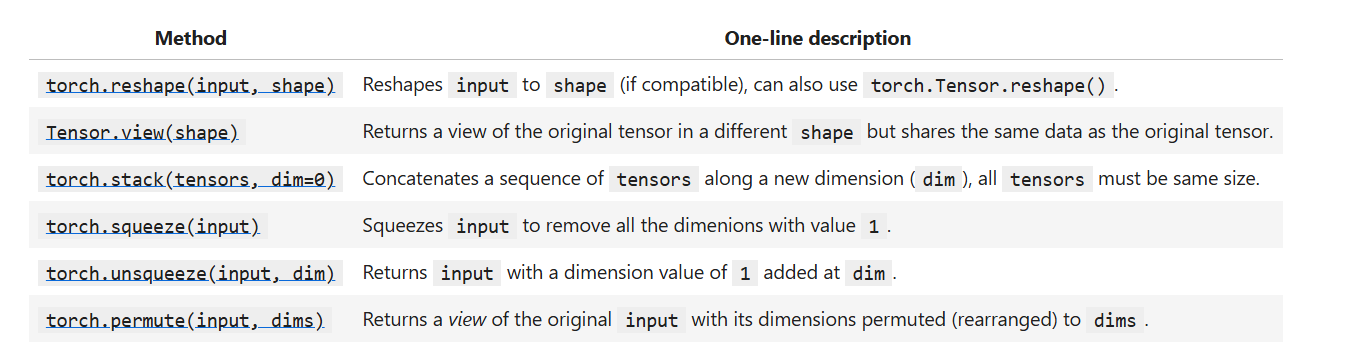

In [ ]:
y = torch.reshape(x,(2,5))
print(x,"\n")
print(y,"\n")
print(torch.reshape(x,(10,1)))

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90]) 

tensor([[ 0, 10, 20, 30, 40],
        [50, 60, 70, 80, 90]]) 

tensor([[ 0],
        [10],
        [20],
        [30],
        [40],
        [50],
        [60],
        [70],
        [80],
        [90]])


In [ ]:
z = x.view(2,5)
print(x, "\n")
print(z) # here x and z, both have same memeory
z[0,3]= 11
z, x

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90]) 

tensor([[ 0, 10, 20, 30, 40],
        [50, 60, 70, 80, 90]])


(tensor([[ 0, 10, 20, 11, 40],
         [50, 60, 70, 80, 90]]),
 tensor([ 0, 10, 20, 11, 40, 50, 60, 70, 80, 90]))

In [ ]:
z_stacked = torch.stack([x,x,x,x], dim = 1)
print(z_stacked, "\n")
z_stacked = torch.stack([x,x,x,x], dim = 0)
print(z_stacked)

tensor([[ 0,  0,  0,  0],
        [10, 10, 10, 10],
        [20, 20, 20, 20],
        [11, 11, 11, 11],
        [40, 40, 40, 40],
        [50, 50, 50, 50],
        [60, 60, 60, 60],
        [70, 70, 70, 70],
        [80, 80, 80, 80],
        [90, 90, 90, 90]]) 

tensor([[ 0, 10, 20, 11, 40, 50, 60, 70, 80, 90],
        [ 0, 10, 20, 11, 40, 50, 60, 70, 80, 90],
        [ 0, 10, 20, 11, 40, 50, 60, 70, 80, 90],
        [ 0, 10, 20, 11, 40, 50, 60, 70, 80, 90]])


In [ ]:
x = torch.arange(1,100, 5)
x.reshape(20,1)
print(x.shape)
a = x.squeeze()
print(a.shape)
a = x.unsqueeze(dim = 1)
print(a.shape)

torch.Size([20])
torch.Size([20])
torch.Size([20, 1])


In [ ]:
x_image = torch.rand(size = (224,224,3))
print(x_image.shape)
x_permuted = x_image.permute(0,2,1)
print(x_permuted.shape)

torch.Size([224, 224, 3])
torch.Size([224, 3, 224])


In [ ]:
x = torch.arange(1,10).reshape(1,3,3)
print(x,"\n")
# we can use : to select all of a target dimension
print(x[:,:,1])
print(x[0,1,1])

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]]) 

tensor([[2, 5, 8]])
tensor(5)


In [ ]:
import numpy as np
# numpy to tensor
array = np.arange(1.,10)
tensor = torch.from_numpy(array) # converting numpy to pytorch by default it converts them to float64
print(array, tensor, tensor.dtype)

# tensor to numpy
tensor = torch.ones(7)
numpy_tensor = tensor.numpy()
print(tensor,numpy_tensor, numpy_tensor.dtype)

[1. 2. 3. 4. 5. 6. 7. 8. 9.] tensor([1., 2., 3., 4., 5., 6., 7., 8., 9.], dtype=torch.float64) torch.float64
tensor([1., 1., 1., 1., 1., 1., 1.]) [1. 1. 1. 1. 1. 1. 1.] float32


In [ ]:
# to make sure the randomness happens only ones to get reproducibility
tensor_A = torch.rand(3,4)
tensor_B = torch.rand(3,4)

print(tensor_A)
print(tensor_B)
print(tensor_A == tensor_B,"\n")

# random seed
random_seed = 42
torch.manual_seed(random_seed)
tensor_c = torch.rand(3,4)
torch.manual_seed(random_seed)
tensor_d = torch.rand(3,4)
print(tensor_c)
print(tensor_d)
print(tensor_c == tensor_d)

tensor([[0.6100, 0.9772, 0.1709, 0.1068],
        [0.2450, 0.4334, 0.5764, 0.3413],
        [0.6178, 0.7863, 0.1318, 0.1398]])
tensor([[0.6187, 0.4117, 0.5148, 0.2125],
        [0.4655, 0.3295, 0.7361, 0.1420],
        [0.2360, 0.9146, 0.5641, 0.0737]])
tensor([[False, False, False, False],
        [False, False, False, False],
        [False, False, False, False]]) 

tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936]])
tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936]])
tensor([[True, True, True, True],
        [True, True, True, True],
        [True, True, True, True]])


In [ ]:
#running tensors and pytorch on GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
torch.cuda.device_count()

cpu


0

In [ ]:
# move tensor to GPU
tensor = torch.rand(2,2)
print(tensor,tensor.device)
device = "cuda" if torch.cuda.is_available() else "cpu"
tensor_on_gpu = tensor.to(device)
print(tensor_on_gpu,tensor_on_gpu.device)

# move tensor back to cpu
# if tensor is on gpu then we cannot transform it into numpy
tensor_cpu = tensor_on_gpu.cpu().numpy()
print(tensor_cpu,tensor.device)

tensor([[0.8694, 0.5677],
        [0.7411, 0.4294]]) cpu
tensor([[0.8694, 0.5677],
        [0.7411, 0.4294]]) cpu
[[0.86940444 0.5677153 ]
 [0.74109405 0.4294045 ]] cpu


# Exercises

**1. Create a random tensor with shape (7, 7).**

In [ ]:
x = torch.rand(7,7)
print(x)

tensor([[0.8854, 0.5739, 0.2666, 0.6274, 0.2696, 0.4414, 0.2969],
        [0.8317, 0.1053, 0.2695, 0.3588, 0.1994, 0.5472, 0.0062],
        [0.9516, 0.0753, 0.8860, 0.5832, 0.3376, 0.8090, 0.5779],
        [0.9040, 0.5547, 0.3423, 0.6343, 0.3644, 0.7104, 0.9464],
        [0.7890, 0.2814, 0.7886, 0.5895, 0.7539, 0.1952, 0.0050],
        [0.3068, 0.1165, 0.9103, 0.6440, 0.7071, 0.6581, 0.4913],
        [0.8913, 0.1447, 0.5315, 0.1587, 0.6542, 0.3278, 0.6532]])


**2. Perform a matrix multiplication on the tensor from exercises 1 with another random tensor with shape (1, 7).**

In [ ]:
y = torch.rand(1,7)
z = torch.matmul(x,y.T)
print(x,"\n")
print(y,"\n")
print(z)

tensor([[0.8854, 0.5739, 0.2666, 0.6274, 0.2696, 0.4414, 0.2969],
        [0.8317, 0.1053, 0.2695, 0.3588, 0.1994, 0.5472, 0.0062],
        [0.9516, 0.0753, 0.8860, 0.5832, 0.3376, 0.8090, 0.5779],
        [0.9040, 0.5547, 0.3423, 0.6343, 0.3644, 0.7104, 0.9464],
        [0.7890, 0.2814, 0.7886, 0.5895, 0.7539, 0.1952, 0.0050],
        [0.3068, 0.1165, 0.9103, 0.6440, 0.7071, 0.6581, 0.4913],
        [0.8913, 0.1447, 0.5315, 0.1587, 0.6542, 0.3278, 0.6532]]) 

tensor([[0.3958, 0.9147, 0.2036, 0.2018, 0.2018, 0.9497, 0.6666]]) 

tensor([[1.7279],
        [1.1168],
        [1.9653],
        [2.4420],
        [1.1902],
        [1.6386],
        [1.5042]])


**3. Set the random seed to 0 and do exercises 1 & 2 over again.**

In [ ]:
seed = 42
torch.manual_seed(seed)
x = torch.rand(7,7)
torch.manual_seed(seed)
y = torch.rand(1,7)

z = torch.matmul(x,y.T)
print(x,"\n")
print(y, "\n")
print(z)

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566],
        [0.7936, 0.9408, 0.1332, 0.9346, 0.5936, 0.8694, 0.5677],
        [0.7411, 0.4294, 0.8854, 0.5739, 0.2666, 0.6274, 0.2696],
        [0.4414, 0.2969, 0.8317, 0.1053, 0.2695, 0.3588, 0.1994],
        [0.5472, 0.0062, 0.9516, 0.0753, 0.8860, 0.5832, 0.3376],
        [0.8090, 0.5779, 0.9040, 0.5547, 0.3423, 0.6343, 0.3644],
        [0.7104, 0.9464, 0.7890, 0.2814, 0.7886, 0.5895, 0.7539]]) 

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566]]) 

tensor([[3.2618],
        [3.4084],
        [2.4866],
        [1.4525],
        [1.7079],
        [2.7291],
        [2.9204]])


**4. Speaking of random seeds, we saw how to set it with torch.manual_seed() but is there a GPU equivalent? If there is, set the GPU random seed to 1234.**

In [ ]:
seed = 1234
torch.cuda.manual_seed(seed)
x = torch.rand(7,7)
torch.cuda.manual_seed(seed)
y = torch.rand(1,7)

z = torch.matmul(x,y.T)
print(x,"\n")
print(y, "\n")
print(z)

tensor([[0.7936, 0.9408, 0.1332, 0.9346, 0.5936, 0.8694, 0.5677],
        [0.7411, 0.4294, 0.8854, 0.5739, 0.2666, 0.6274, 0.2696],
        [0.4414, 0.2969, 0.8317, 0.1053, 0.2695, 0.3588, 0.1994],
        [0.5472, 0.0062, 0.9516, 0.0753, 0.8860, 0.5832, 0.3376],
        [0.8090, 0.5779, 0.9040, 0.5547, 0.3423, 0.6343, 0.3644],
        [0.7104, 0.9464, 0.7890, 0.2814, 0.7886, 0.5895, 0.7539],
        [0.1952, 0.0050, 0.3068, 0.1165, 0.9103, 0.6440, 0.7071]]) 

tensor([[0.6581, 0.4913, 0.8913, 0.1447, 0.5315, 0.1587, 0.6542]]) 

tensor([[2.0634],
        [1.9886],
        [1.5235],
        [2.0065],
        [2.2234],
        [2.6824],
        [1.4699]])


**5. Create two random tensors of shape (2, 3) and send them both to the GPU (you'll need access to a GPU for this). Set torch.manual_seed(1234) when creating the tensors (this doesn't have to be the GPU random seed).**

In [ ]:
torch.manual_seed(1234)
x = torch.rand(2,3)
torch.manual_seed(1234)
y = torch.rand(2,3)
print(x.device)
print(y.device)

device = "cuda" if torch.cuda.is_available() else "cpu"
x_gpu = x.to(device)
print(x_gpu.device)
y_gpu = y.to(device)
print(y_gpu.device)

cpu
cpu
cpu
cpu


**6. Perform a matrix multiplication on the tensors you created in 5**

In [ ]:
z = torch.matmul(x_gpu,y_gpu.T)
print(z)

tensor([[0.2299, 0.2161],
        [0.2161, 0.6287]])


**7. Find the maximum and minimum values of the output of 6**

In [ ]:
z_max = torch.max(z)
print(z_max)
z_min = torch.min(z)
print(z_min)

tensor(0.6287)
tensor(0.2161)


8. **Find the maximum and minimum index values of the output of 6.**

In [ ]:
z_max_index = torch.argmax(z)
print(z_max_index)
z_min_index = torch.argmin(z)
print(z_min_index)

tensor(3)
tensor(1)


9. **Make a random tensor with shape (1, 1, 1, 10) and then create a new tensor with all the 1 dimensions removed to be left with a tensor of shape (10). Set the seed to 7 when you create it and print out the first tensor and it's shape as well as the second tensor and it's shape.**

In [ ]:
torch.manual_seed(7)
x = torch.rand(1,1,1,10)
print(x.shape)
x_mindim = torch.squeeze(x)
print(x_mindim.shape)


torch.Size([1, 1, 1, 10])
torch.Size([10])


# Chapter - 2

In [ ]:
import torch
from torch import nn # nn contains all pytorch building blocks for neural network
import matplotlib.pyplot as plt

# to check pytorch version
print(torch.__version__)

2.10.0+cpu


## Linear Regression

In [ ]:
weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.02
X = torch.arange(start,end,step).unsqueeze(dim = 1)
Y = weight*X +bias
print(len(X),len(Y))

50 50


40 40 10 10


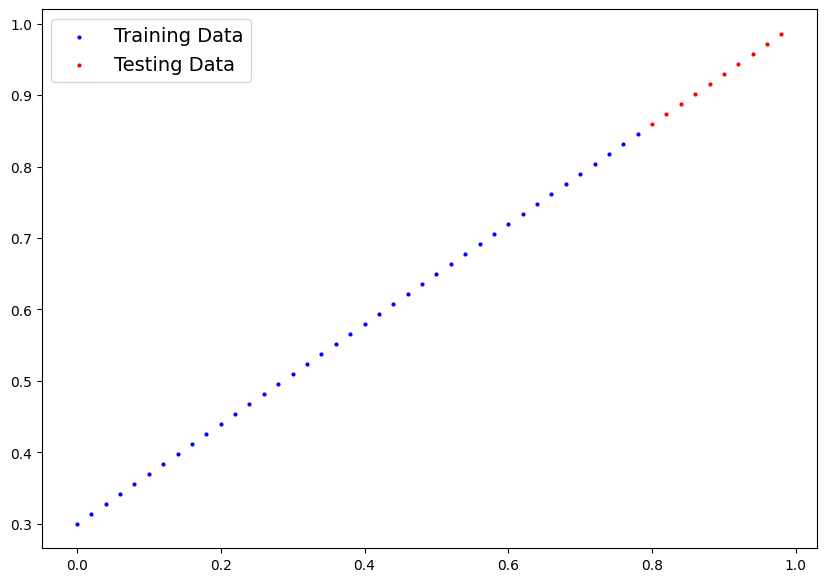

In [ ]:
# train test split
train_split = int(0.8* len(X))
X_train, Y_train = X[:train_split],Y[:train_split]
X_test,Y_test = X[train_split:], Y[train_split:]
print(len(X_train),len(Y_train),len(X_test),len(Y_test))

def plot_pred(train_data = X_train,
              train_label = Y_train,
              test_data = X_test,
              test_label = Y_test,
              prediction = None):
  """
  Plotting train and test data
  """
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_label, c ='b',s = 4, label = "Training Data")
  plt.scatter(test_data,test_label, c ='r',s = 4, label = "Testing Data")
  if prediction is not None:
    plt.scatter(test_data, prediction,c = 'g', s = 4, label = "Predictions")

  plt.legend(prop = {"size":14});# passing a dictionary of size

plot_pred()

It is the base class for all neural network models in PyTorch.
So your model automatically gets:

- parameter tracking

- forward() handling

- parameters()

- to(device)

- eval()

- train()

- saving/loading support

- autograd compatibility

In [ ]:
# Linear Regression Model
class LinearRegressionModel(nn.Module): # it is inheriting from nn.module
    def __init__(self):
      super().__init__()
      self.weights = nn.Parameter(torch.randn(1,
                                              requires_grad = True,
                                              dtype = torch.float))# by default it takes float32
      # Creates a tensor of shape (1,) Filled with random numbers from a normal distribution.
      self.bias = nn.Parameter(torch.randn(1,
                                              requires_grad = True,
                                              dtype = torch.float))

    def forward(self,x: torch.Tensor) -> torch.Tensor:
       """
       the annotation (self,x: torch.Tensor) -> torch.Tensor: means x is expected to be a torch.Tensor
       and This function returns a torch.Tensor
       """
       return self.weights*x + self.bias


Gradient of a function alwwys gives steepest ascend

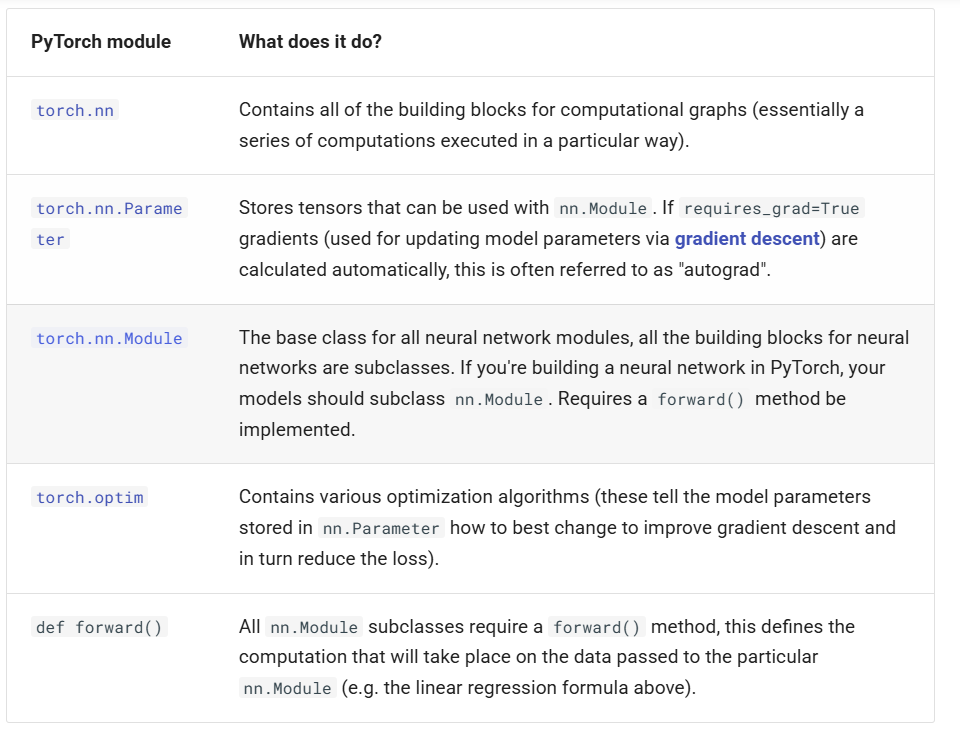

In [ ]:
# checking the contents of a model
torch.manual_seed(42)
model_0 = LinearRegressionModel()
print(list(model_0.parameters()), "\n")
# list named paramteres
model_0.state_dict()

[Parameter containing:
tensor([0.3367], requires_grad=True), Parameter containing:
tensor([0.1288], requires_grad=True)] 



OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

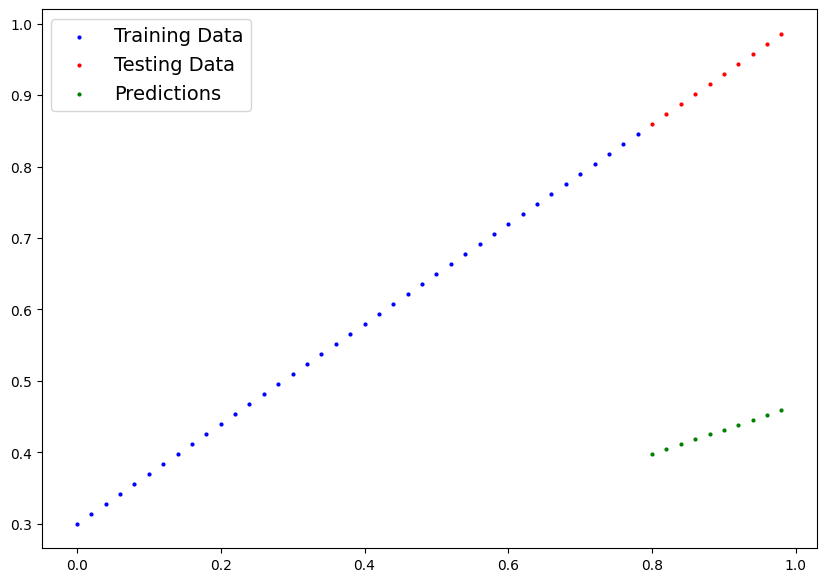

In [ ]:
# predict our random initialized model
# we could also use torch.no_grad() for the same
with torch.inference_mode(): # context managers it turns of gradient tracking so mostly used during testing
  y_pred = model_0(X_test)

plot_pred(prediction = y_pred)

* Loss function is also called as Criterion
* Optimizer takes into account of the loss values and adjust the parameters

In [ ]:
# loss function
loss_fn = nn.L1Loss()

# optimizer
""" torch.optim has different optimizer """
optimizer = torch.optim.SGD(params = model_0.parameters(),
                              lr = 0.01)

there are two model eval() and train() mode

In [ ]:
# training a model

# how many times loop through the data
epochs = 200
epoch_count = []
loss_values = []
test_loss_values = []

for epoch in range(epochs):
  model_0.train() # it initializes all requires_grad is made as required gradient
  y_pred = model_0(X_train)
  # loss calculation
  loss = loss_fn(y_pred,Y_train)
  optimizer.zero_grad() # to avoid optimizer accumulation in the subsequent loop
  # backpropgation
  loss.backward()
  # gradient descent
  optimizer.step() # each step gets accumulated
  model_0.eval() # it turns off different models like BatchNorm Layers, Dropout
  with torch.inference_mode():#turns off Gradient Tracking and .no_grad() also does the same thing in older version
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred,Y_test)
  if epoch % 10 == 0:
    epoch_count.append(epoch)
    loss_values.append(loss)
    test_loss_values.append(test_loss)
    print(f"Epoch : {epoch} | Loss: {loss} | Test Loss: {test_loss}")
    print(model_0.state_dict())

Epoch : 0 | Loss: 0.31288138031959534 | Test Loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch : 10 | Loss: 0.1976713240146637 | Test Loss: 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch : 20 | Loss: 0.08908725529909134 | Test Loss: 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch : 30 | Loss: 0.053148526698350906 | Test Loss: 0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch : 40 | Loss: 0.04543796554207802 | Test Loss: 0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch : 50 | Loss: 0.04167863354086876 | Test Loss: 0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch : 60 | Loss: 0.03818932920694351 | Test Loss: 0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
Epoch : 70 | Lo

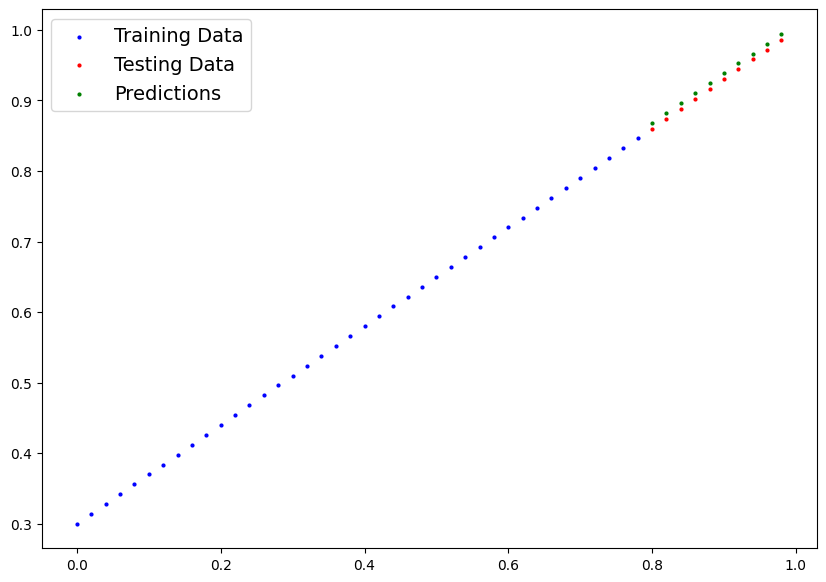

In [ ]:
plot_pred(prediction = test_pred)

/tmp/ipykernel_255/2826395484.py:1: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()),label = "Train Loss")


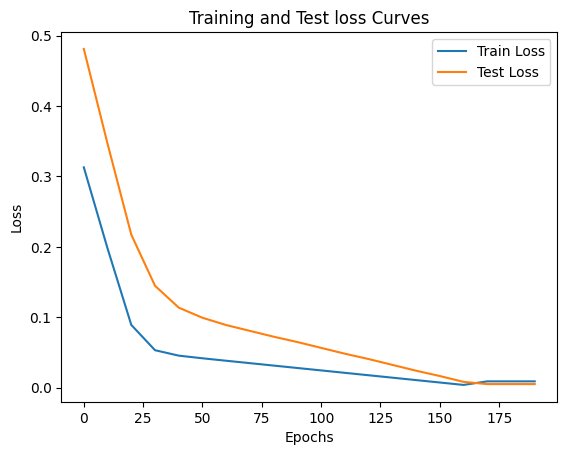

In [ ]:
plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()),label = "Train Loss")
plt.plot(epoch_count, np.array(torch.tensor(test_loss_values).numpy()), label = "Test Loss")
plt.title("Training and Test loss Curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

## Saving a model in pytorch

There are mainly three ways to save and load a model in pytorch:
1. `torch.save()` - allows to save python object in a python's pickle format.
2. `torch.load()` - allows to load a saved python object
3. `torch.nn.Module.load_state_dict()` - allows to load a saved model's state dictionary.

In [ ]:
# saving a model in pytorch
from pathlib import Path
# create model directory
Model_path = Path("models")
Model_path.mkdir(parents=True,exist_ok = True)
#create model save path
Model_name = "python_workflow.pth"
Model_save_path = Model_path/Model_name
#save the model state dict
print(f"Saving model to :{Model_save_path}")
torch.save(obj=model_0.state_dict(),f=Model_save_path)

Saving model to :models/python_workflow.pth


In [ ]:
ls -l models

total 4
-rw-r--r-- 1 root root 1957 Mar 23 12:36 python_workflow.pth


For loading the state we create a new instance of our model and load the saved `state_dict()` into that

In [ ]:
loaded_model_0 = LinearRegressionModel()
loaded_model_0.load_state_dict(torch.load(f=Model_save_path))

<All keys matched successfully>

In [ ]:
# verifying the model saved data
loaded_model_0.eval()
with torch.inference_mode():
  loaded_model_preds = loaded_model_0(X_test)

model_0.eval()
with torch.inference_mode():
  y_preds = loaded_model_0(X_test)

y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## putting all together and forming a pipeline

Device used: cpu
40 40 10 10


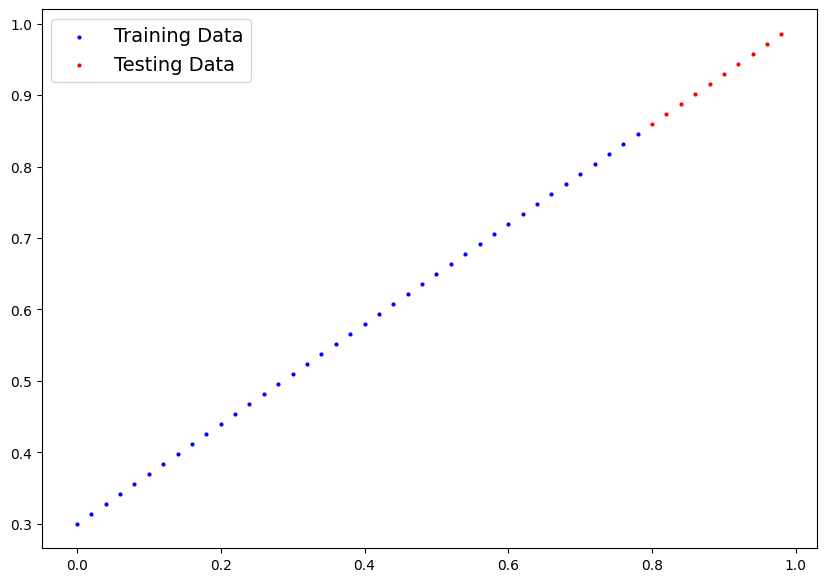

In [ ]:
import matplotlib.pyplot as plt
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device used: {device}")

# data creation
weight,bias = 0.7,0.3
start,end,step = 0,1,0.02
x = torch.arange(start,end,step).unsqueeze(dim=1)
y = weight*x + bias

#split data
train_split = int(0.8*len(x))
X_train, Y_train = x[:train_split], y[:train_split]
X_test, Y_test = x[train_split:], y[train_split:]
print(len(X_train),len(Y_train),len(X_test),len(Y_test))
plot_pred(X_train,Y_train,X_test,Y_test)

In [ ]:
class LinearRegressionModelv2(nn.Module):
  def __init__(self):
    super().__init__()
    self.Linear_layer = nn.Linear(in_features=1,
                                  out_features=1) #it creates both weight and bias parameter for the different layers
    # linear transform,probing layer, fully connected layer, dense layer are all same it is represented by the above line.
  def forward(self,x:torch.Tensor)-> torch.Tensor:
    return self.Linear_layer(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelv2()
model_1.state_dict()

OrderedDict([('Linear_layer.weight', tensor([[0.7645]])),
             ('Linear_layer.bias', tensor([0.8300]))])

In [ ]:
#check model current device
next(model_1.parameters()).device
# to change the device we use model_1.to(device)
#loss function and optimizer
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.01)
torch.manual_seed(42)
epochs = 200
for epoch in range(epochs):
  model_1.train()
  y_pred = model_1(X_train)
  loss = loss_fn(y_pred,Y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  #testing
  model_1.eval()
  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred,Y_test)
  if epoch % 10 == 0:
    print(f"Epoch : {epoch} | Loss : {loss} | Test loss: {test_loss}")

Epoch : 0 | Loss : 0.5436569452285767 | Test loss: 0.5605052709579468
Epoch : 10 | Loss : 0.42844706773757935 | Test loss: 0.42579537630081177
Epoch : 20 | Loss : 0.31323719024658203 | Test loss: 0.2910855710506439
Epoch : 30 | Loss : 0.1980273276567459 | Test loss: 0.1563757359981537
Epoch : 40 | Loss : 0.0828174576163292 | Test loss: 0.021665919572114944
Epoch : 50 | Loss : 0.023356426507234573 | Test loss: 0.048834484070539474
Epoch : 60 | Loss : 0.019609849900007248 | Test loss: 0.04538799077272415
Epoch : 70 | Loss : 0.01618141308426857 | Test loss: 0.03711546212434769
Epoch : 80 | Loss : 0.012742981314659119 | Test loss: 0.028842901811003685
Epoch : 90 | Loss : 0.0093079237267375 | Test loss: 0.02125726267695427
Epoch : 100 | Loss : 0.005878164432942867 | Test loss: 0.012984687462449074
Epoch : 110 | Loss : 0.002439356641843915 | Test loss: 0.004712158348411322
Epoch : 120 | Loss : 0.010256484150886536 | Test loss: 0.0003308236482553184
Epoch : 130 | Loss : 0.010256484150886536 |

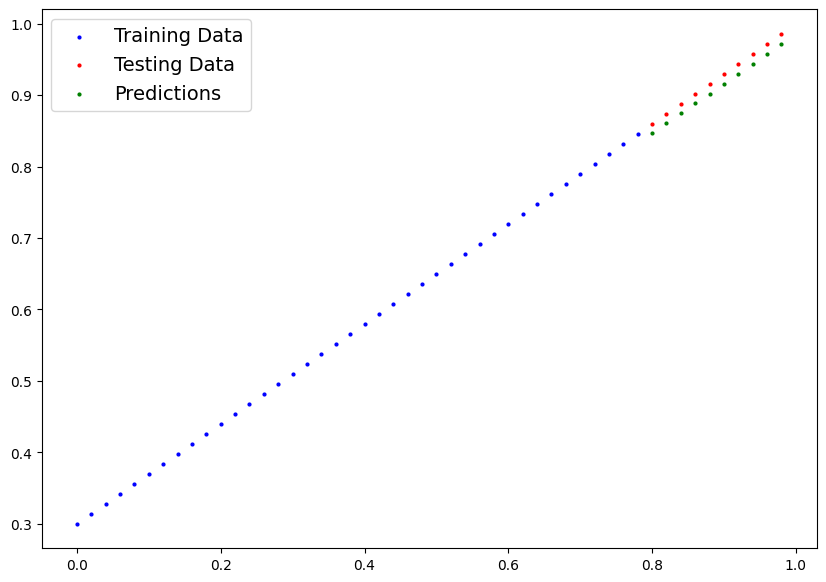

In [ ]:
# making predictions
model_1.eval()
with torch.inference_mode():
  y_preds = model_1(X_test)

plot_pred(prediction = y_preds.cpu())

# Chapter 2:

##Neural network classification

- each input image has width, height and color channel
- batch size represents how many image the algorithm looks together
- output will always be a prediction probability score for each classes.
- `torch.nn` includes all neural layers needed to built a neural network.
- `torch.optim` have set of all optimizers

In [ ]:
import sklearn
from sklearn.datasets import make_circles

n_samples = 1000
# make dataset
X,y = make_circles(n_samples,
                    noise = 0.03,
                    random_state = 42)
print(len(X),len(y))
print(f"First 5 samples of X :\n {X[:5]}")
print(f"First 5 samples of y :\n {y[:5]}")

1000 1000
First 5 samples of X :
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 samples of y :
 [1 1 1 1 0]


In [ ]:
# creating a dataframe
import pandas as pd
circles = pd.DataFrame({"x1": X[:,0],
                        "x2": X[:,1],
                        "Label": y})
circles.head(10)

,x1,x2,Label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


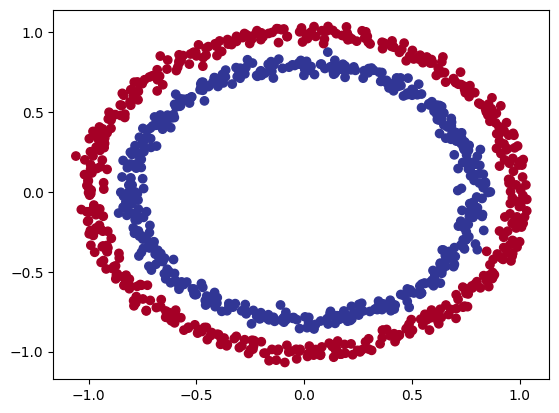

In [ ]:
# visualize the data
import matplotlib.pyplot as plt
plt.scatter(x = X[:,0],
            y = X[:,1],
            c = y, # which data to colour
            cmap = plt.cm.RdYlBu);#cm means colour map and RdYlBu means red,yellow,blue

In [ ]:
# check input and output shapes
print(X.shape,y.shape)
x_sample = X[0]
y_sample = y[0]

print(f"Values for one sample of x : {x_sample} and for the value of y :{y_sample}")
print(f"shapes for one sample of x : {x_sample.shape} and for the shape of y :{y_sample.shape}")

(1000, 2) (1000,)
Values for one sample of x : [0.75424625 0.23148074] and for the value of y :1
shapes for one sample of x : (2,) and for the shape of y :()


In [ ]:
#check torch version
import torch
torch.__version__

'2.10.0+cpu'

In [ ]:
print(type(X))
x_tensor = torch.from_numpy(X).type(torch.float)
y_tensor = torch.from_numpy(y).type(torch.float)
print(type(x_tensor), y_tensor.dtype)
print(x_tensor[:5], "\n",y_tensor[:5])

<class 'numpy.ndarray'>
<class 'torch.Tensor'> torch.float32
tensor([[ 0.7542,  0.2315],
        [-0.7562,  0.1533],
        [-0.8154,  0.1733],
        [-0.3937,  0.6929],
        [ 0.4422, -0.8967]]) 
 tensor([1., 1., 1., 1., 0.])


In [ ]:
# split data into train and test split
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x_tensor
                                                 ,y_tensor,
                                                 test_size = 0.2,# 20% data will be test
                                                 random_state = 42)
print(len(x_train),len(y_train),len(x_test),len(y_test))

800 800 200 200


In [ ]:
# building the model
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features = 2,
                             out_features = 5) # takes in 2 features and upscales to 5 features
    self.layer_2 = nn.Linear(in_features = 5,
                             out_features = 1) # takes 5 features from previous layer and output a single feature which is same as y

def forward(self,x):
  return self.layer_2(self.layer_1(x)) # x -> layer_1 -> layer_2 -> output

model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
next(model_0.parameters()).device

device(type='cpu')

In [ ]:
# start from 9:36:30